# Modelo 3 · Próximo movimiento de la competencia
## Notebook 1: los datos

**El problema.** Los competidores de Pycca cambian sus precios todo el tiempo: ofertas de fin de semana, inicio de mes, Black Friday, Navidad. Hoy Pycca reacciona cuando el competidor ya bajó. Queremos **anticipar** qué producto va a bajar, en qué comercio y cuándo.

**Los datos son sintéticos pero calibrados con lo real.** Medimos cómo se mueven los precios de 13 competidores en lecturas reales de sus webs (octubre–noviembre 2026) y simulamos 3 años diarios con esas mismas tasas. Ningún precio, producto ni comercio es real (`C01`, `P00001`…).

Este notebook muestra qué hay en los datos y qué patrones tienen. Esos patrones son los que un modelo puede aprender.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
RAIZ = Path('..') if Path('../variables.py').exists() else Path('.')     # repo (notebooks/) o paquete de ESPOL
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, '.')
import estilo; estilo.aplicar()
from estilo import AZUL, NARANJA, AQUA, TINTA2, GRIS, pie
DATOS = RAIZ / 'datos'
pd.set_option('display.width', 160)

### 1. Qué hay en los datos

In [2]:
d = pd.read_parquet(DATOS / 'precios_diarios.parquet')
prod = pd.read_csv(DATOS / 'productos.csv'); com = pd.read_csv(DATOS / 'comercios.csv')
cal = pd.read_csv(DATOS / 'calendario.csv', parse_dates=['fecha'])
d = d.merge(prod, on='producto_id').sort_values(['comercio_id', 'producto_id', 'fecha'])
print(f"{len(d):,} filas | {d.groupby(['comercio_id','producto_id']).ngroups:,} series (producto x comercio) | "
      f"{d.producto_id.nunique():,} productos | {d.comercio_id.nunique()} comercios | {d.fecha.min().date()} a {d.fecha.max().date()}")
d.head()

3,297,792 filas | 3,616 series (producto x comercio) | 1,500 productos | 13 comercios | 2023-01-01 a 2025-06-30


,fecha,comercio_id,producto_id,precio_vigente,precio_normal,en_oferta,disponible,division
5,2023-01-01,C01,P00003,6.94,6.94,False,True,PAPELERIA & REGALERIA
3621,2023-01-02,C01,P00003,6.94,6.94,False,True,PAPELERIA & REGALERIA
7237,2023-01-03,C01,P00003,6.94,6.94,False,True,PAPELERIA & REGALERIA
10853,2023-01-04,C01,P00003,6.94,6.94,False,True,PAPELERIA & REGALERIA
14469,2023-01-05,C01,P00003,NaN,NaN,<NA>,<NA>,PAPELERIA & REGALERIA


In [3]:
com

,comercio_id,tipo,tachado_permanente
0,C01,hipermercado,False
1,C02,electro con credito,False
2,C03,ferreteria y hogar,False
3,C04,electro con credito,False
4,C05,papeleria y hogar,False
5,C06,departamental,False
6,C07,departamental,False
7,C08,hogar,False
8,C09,tecnologia,False
9,C10,hogar,True


### 2. Cómo se ve una serie de precios

El mismo producto en varios comercios a la vez. Las caídas son ofertas: duran unos días y el precio vuelve. Cuando un comercio baja, otro suele seguirlo poco después: eso es lo que el modelo puede anticipar.

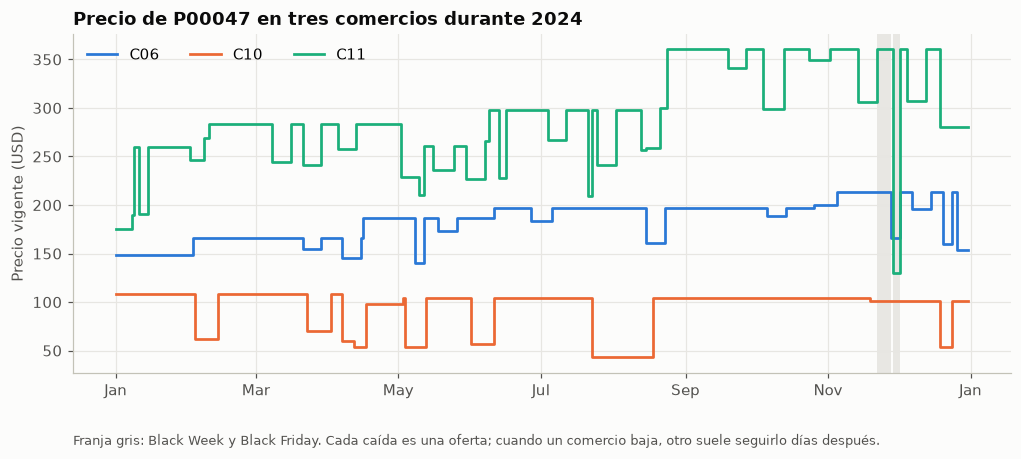

In [4]:
d['baja5'] = d.groupby(['comercio_id', 'producto_id']).precio_vigente.pct_change() < -0.05
x = d[(d.fecha >= '2024-01-01') & (d.fecha <= '2024-12-31')]
n_com = x.groupby('producto_id').comercio_id.nunique()
cand = x[x.producto_id.isin(n_com[n_com == 3].index)].groupby('producto_id').baja5.sum()
p_ej = cand.idxmax()
g = x[x.producto_id == p_ej]
fig, ax = plt.subplots(figsize=(11, 4))
for c, col in zip(sorted(g.comercio_id.unique()), estilo.SERIES):
    s = g[g.comercio_id == c].set_index('fecha').precio_vigente.ffill()
    ax.step(s.index, s.values, where='post', color=col, lw=1.8, label=c)
for _, e in cal[cal.evento.str.startswith('Black') & (cal.fecha.dt.year == 2024)].groupby('evento').fecha.agg(['min', 'max']).iterrows():
    ax.axvspan(e['min'], e['max'], color=GRIS, alpha=0.35, lw=0)
ax.set_title(f'Precio de {p_ej} en tres comercios durante 2024')
ax.set_ylabel('Precio vigente (USD)'); ax.legend(ncol=3, loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
pie(ax, 'Franja gris: Black Week y Black Friday. Cada caída es una oferta; cuando un comercio baja, otro suele seguirlo días después.')
plt.show()

### 3. La temporada manda

Parte de las series en oferta cada día. Los picos son Black Friday, Navidad y las liquidaciones de inicio de año: el calendario explica mucho de cuándo baja la competencia.

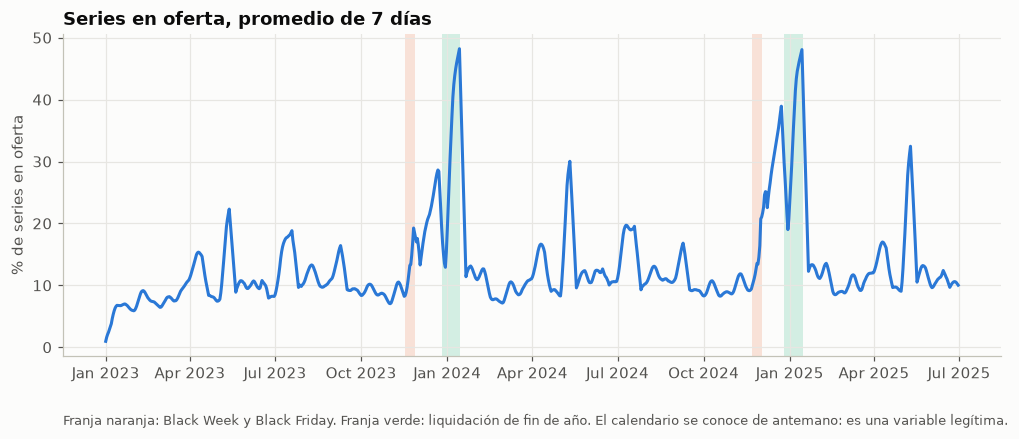

In [5]:
s = d.groupby('fecha').en_oferta.mean().rolling(7, min_periods=1).mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(s.index, s.values, color=AZUL)
for ev, col in (('Black', NARANJA), ('Liquidacion de fin', AQUA)):
    ce = cal[cal.evento.str.startswith(ev)].sort_values('fecha')
    tramo = (ce.fecha.diff() != pd.Timedelta(days=1)).cumsum()          # bloques de dias seguidos
    for _, e in ce.groupby(tramo).fecha.agg(['min', 'max']).iterrows():
        if e['min'] <= s.index.max():
            ax.axvspan(e['min'], min(e['max'], s.index.max()), color=col, alpha=0.18, lw=0)
ax.set_title('Series en oferta, promedio de 7 días'); ax.set_ylabel('% de series en oferta')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
pie(ax, 'Franja naranja: Black Week y Black Friday. Franja verde: liquidación de fin de año. El calendario se conoce de antemano: es una variable legítima.')
plt.show()

### 4. Cada comercio tiene su ritmo

Probabilidad de que una serie baje al menos 5 % según el día de la semana. Algunos comercios bajan casi siempre el jueves o viernes (ofertas de fin de semana), otros a inicio de mes o en quincena.

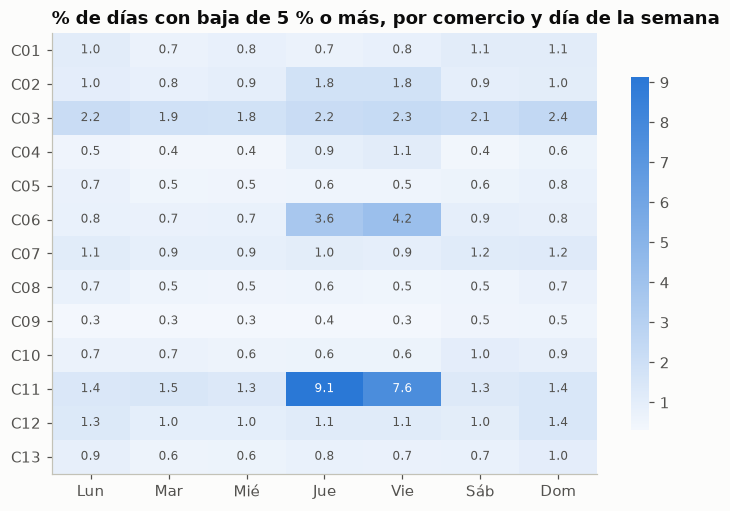

In [6]:
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
t = d.assign(ds=d.fecha.dt.weekday).groupby(['comercio_id', 'ds']).baja5.mean().unstack() * 100
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('azul', ['#f3f7fd', AZUL])
fig, ax = plt.subplots(figsize=(8, 5.2))
im = ax.imshow(t.values, cmap=cmap, aspect='auto')
ax.set_xticks(range(7), dias); ax.set_yticks(range(len(t)), t.index); ax.grid(False)
for i in range(t.shape[0]):
    for j in range(7):
        ax.text(j, i, f'{t.values[i, j]:.1f}', ha='center', va='center', fontsize=8, color='white' if t.values[i, j] > t.values.max() * 0.6 else TINTA2)
ax.set_title('% de días con baja de 5 % o más, por comercio y día de la semana')
plt.colorbar(im, ax=ax, shrink=0.8).outline.set_visible(False)
plt.show()

### 5. Contagio entre comercios

Si otro comercio bajó el mismo producto en los últimos 3 días, ¿es más probable que este baje hoy? Sí: es la señal de "líder y seguidores".

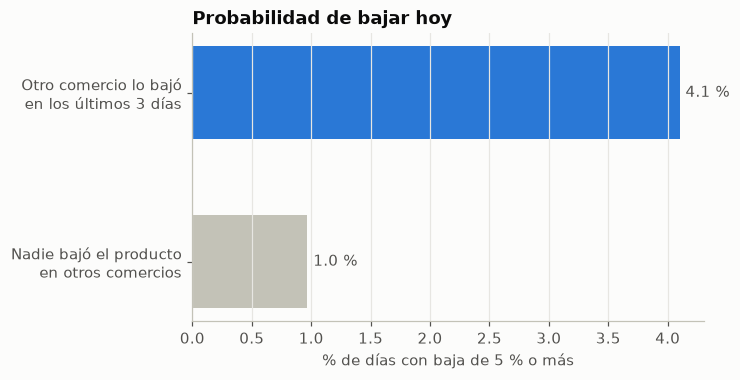

Contagio: 4.2 veces más probable si otro comercio bajó


In [7]:
d['_b'] = d.baja5.astype(int)
por = d.groupby(['producto_id', 'fecha'])._b.sum().rename('bajas_dia')
d2 = d.join(por, on=['producto_id', 'fecha'])
d2['otros_3d'] = d2.groupby(['comercio_id', 'producto_id']).bajas_dia.transform(lambda z: z.shift(1).rolling(3, min_periods=1).sum()) \
    - d2.groupby(['comercio_id', 'producto_id'])._b.transform(lambda z: z.shift(1).rolling(3, min_periods=1).sum())
r = d2.dropna(subset=['otros_3d']).groupby(d2.otros_3d > 0).baja5.mean() * 100
fig, ax = plt.subplots(figsize=(6, 3.4))
b = ax.barh(['Nadie bajó el producto\nen otros comercios', 'Otro comercio lo bajó\nen los últimos 3 días'], r.values, color=[GRIS, AZUL], height=0.55)
for rect, v in zip(b, r.values):
    ax.text(v + 0.05, rect.get_y() + rect.get_height() / 2, f'{v:.1f} %', va='center', color=TINTA2)
ax.set_title('Probabilidad de bajar hoy'); ax.set_xlabel('% de días con baja de 5 % o más'); ax.grid(axis='y', visible=False)
plt.show()
print(f'Contagio: {r[True] / r[False]:.1f} veces más probable si otro comercio bajó')

### 6. ¿Se parece a lo real?

Para cada comercio comparamos las tasas medidas en las lecturas reales (22/10–09/11/2026) con las de la sintética en la misma ventana del año. Cada punto es un comercio; sobre la diagonal, la sintética reproduce lo real.

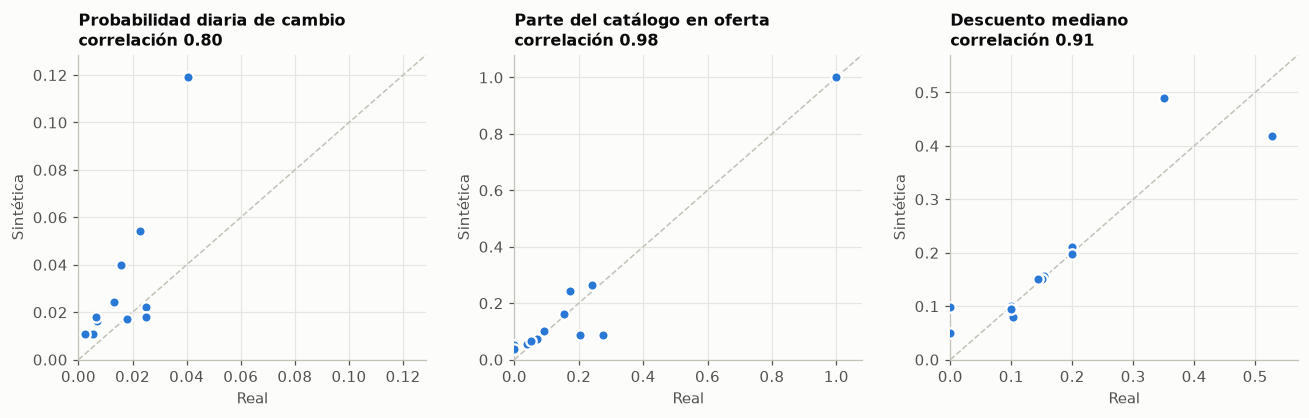

In [8]:
v = pd.read_csv(RAIZ / 'validacion.csv')
fig, axs = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (a, b, t) in zip(axs, [('cambio_diario_real', 'cambio_diario_sint', 'Probabilidad diaria de cambio'),
                                ('en_oferta_real', 'en_oferta_sint', 'Parte del catálogo en oferta'),
                                ('descuento_real', 'descuento_sint', 'Descuento mediano')]):
    ax.scatter(v[a], v[b], s=46, color=AZUL, edgecolor='white', linewidth=1.5, zorder=3)
    m = max(v[a].max(), v[b].max()) * 1.08
    ax.plot([0, m], [0, m], color=GRIS, lw=1, ls='--'); ax.set_xlim(0, m); ax.set_ylim(0, m)
    ax.set_title(f'{t}\ncorrelación {v[a].corr(v[b]):.2f}', fontsize=10.5); ax.set_xlabel('Real'); ax.set_ylabel('Sintética')
plt.tight_layout(); plt.show()

**Resumen.** La sintética reproduce cuánto cambia el precio, qué parte está en oferta y cuánto descuenta cada comercio. Lo que **no** se pudo medir con dos semanas reales y es **supuesto**: el calendario anual, el ritmo de cada comercio, la duración fija de las ofertas, la presión competitiva y el contagio (más marcado que en lo real, para que sea aprendible).

Siguiente: **02_baseline.ipynb**, la tarea y el modelo a superar.